In [ ]:
!wget -q --show-progress \
"https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-01.parquet" \
-O yellow_tripdata_2025-01.parquet


yellow_tripdata_202 100%[===================>]  56.42M   184MB/s    in 0.3s    


In [ ]:
import pandas as pd

df = pd.read_parquet("yellow_tripdata_2025-01.parquet")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (3475226, 20)

Columns:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee']

First 5 rows:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.0,1.60,1.0,N,229,237,1,10.0,3.5,0.5,3.00,0.0,1.0,18.00,2.5,0.0,0.0
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.0,0.50,1.0,N,236,237,1,5.1,3.5,0.5,2.02,0.0,1.0,12.12,2.5,0.0,0.0
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.0,0.60,1.0,N,141,141,1,5.1,3.5,0.5,2.00,0.0,1.0,12.10,2.5,0.0,0.0
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.0,0.52,1.0,N,244,244,2,7.2,1.0,0.5,0.00,0.0,1.0,9.70,0.0,0.0,0.0
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.0,0.66,1.0,N,244,116,2,5.8,1.0,0.5,0.00,0.0,1.0,8.30,0.0,0.0,0.0


In [ ]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Pickup zones:", df["PULocationID"].nunique())


Missing values: 2700745
Duplicate rows: 0
Pickup zones: 261


In [ ]:
missing = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing_count": missing,
    "Missing_percentage": (missing/len(df))*100
})

missing_report = missing_report[
    missing_report["Missing_count"] > 0
].sort_values("Missing_percentage", ascending=False)

display(missing_report.round(2))

,Missing_count,Missing_percentage
passenger_count,540149,15.54
RatecodeID,540149,15.54
store_and_fwd_flag,540149,15.54
congestion_surcharge,540149,15.54
Airport_fee,540149,15.54


In [ ]:
# check the two essential colummns
print("Missing pickup timestamps:",
      df["tpep_pickup_datetime"].isnull().sum())

print("Missing pickup-zone IDs:",
      df["PULocationID"].isnull().sum())

# check the data types
print("\nPickup timestamp data type:",
      df["tpep_pickup_datetime"].dtype)

print("Pickup-zone ID date type:",
      df["PULocationID"].dtype)

# check pickup timestamps outside January 2025
pickup_time = df["tpep_pickup_datetime"]

print("\nEarliest pickup:", pickup_time.min())
print("Latest pickup:", pickup_time.max())

Missing pickup timestamps: 0
Missing pickup-zone IDs: 0

Pickup timestamp data type: datetime64[us]
Pickup-zone ID date type: int32

Earliest pickup: 2024-12-31 20:47:55
Latest pickup: 2025-02-01 00:00:44


In [ ]:
pickup_time = df["tpep_pickup_datetime"]

# count trip by calender month
print("trips by month:")
display(pickup_time.dt.to_period("M").value_counts().sort_index())

# count records outside January 2025
outside_january = (
    (pickup_time < "2025-01-01") |
    (pickup_time >= "2025-02-01")
)

print("\nRecords outside January 2025:",
      outside_january.sum())

trips by month:


,count
tpep_pickup_datetime,
2024-12,21
2025-01,3475204
2025-02,1



Records outside January 2025: 22


In [ ]:
# keep only trips picked up during January 2025
january_df = df.loc[
    (df["tpep_pickup_datetime"] >= "2025-01-01") &
    (df["tpep_pickup_datetime"] < "2025-02-01"),
    ["tpep_pickup_datetime", "PULocationID"]
].copy()

print("original datset shape:", df.shape)
print("january working dataset shape:", january_df.shape)

display(january_df.head())

original datset shape: (3475226, 20)
january working dataset shape: (3475204, 2)


,tpep_pickup_datetime,PULocationID
0,2025-01-01 00:18:38,229
1,2025-01-01 00:32:40,236
2,2025-01-01 00:44:04,141
3,2025-01-01 00:14:27,244
4,2025-01-01 00:21:34,244


In [ ]:
# Round each pickup time down to the start of its hour
january_df["pickup_hour"] = (
    january_df["tpep_pickup_datetime"].dt.floor("h")
)

# Count trips in each hour for each pickup zone
hourly_demand = (
    january_df
    .groupby(["pickup_hour", "PULocationID"])
    .size()
    .reset_index(name="trip_count")
)

print("Hourly demand dataset shape:", hourly_demand.shape)
display(hourly_demand.head(10))


Hourly demand dataset shape: (97014, 3)


,pickup_hour,PULocationID,trip_count
0,2025-01-01,4,28
1,2025-01-01,7,12
2,2025-01-01,9,1
3,2025-01-01,10,1
4,2025-01-01,12,1
5,2025-01-01,13,9
6,2025-01-01,14,4
7,2025-01-01,15,1
8,2025-01-01,16,1
9,2025-01-01,17,5


In [ ]:
print("Total trips before aggregation:", len(january_df))
print("Total trips after aggregation:", hourly_demand["trip_count"].sum())

print("\nUnique pickup hours:",
      hourly_demand["pickup_hour"].nunique())

print("Unique pickup zones:",
      hourly_demand["PULocationID"].nunique())

print("\nEarliest hour:", hourly_demand["pickup_hour"].min())
print("Latest hour:", hourly_demand["pickup_hour"].max())

print("\nMissing values:")
display(hourly_demand.isnull().sum())


Total trips before aggregation: 3475204
Total trips after aggregation: 3475204

Unique pickup hours: 744
Unique pickup zones: 261

Earliest hour: 2025-01-01 00:00:00
Latest hour: 2025-01-31 23:00:00

Missing values:


,0
pickup_hour,0
PULocationID,0
trip_count,0


In [ ]:
# Calculate total January trips for each pickup zone
zone_demand = (
    hourly_demand
    .groupby("PULocationID")["trip_count"]
    .sum()
    .sort_values(ascending=False)
)

# Display the 15 busiest pickup zones
print("Top 15 pickup zones by January trip volume:")
display(zone_demand.head(15).reset_index(name="total_trips"))


Top 15 pickup zones by January trip volume:


,PULocationID,total_trips
0,161,169977
1,237,163703
2,236,155647
3,132,146135
4,230,125829
5,186,119130
6,162,117930
7,142,110584
8,239,96614
9,163,95905


In [ ]:
# Select the 10 busiest zones for our prototype
top_zones = zone_demand.head(10).index.tolist()

print("Selected pickup zones:", top_zones)

# Count how many distinct hours contain recorded trips per zone
hours_per_zone = (
    hourly_demand[hourly_demand["PULocationID"].isin(top_zones)]
    .groupby("PULocationID")["pickup_hour"]
    .nunique()
)

print("\nRecorded hours per selected zone:")
display(hours_per_zone.reset_index(name="hours_with_demand"))


Selected pickup zones: [161, 237, 236, 132, 230, 186, 162, 142, 239, 163]

Recorded hours per selected zone:


,PULocationID,hours_with_demand
0,132,743
1,142,740
2,161,744
3,162,742
4,163,741
5,186,744
6,230,743
7,236,727
8,237,738
9,239,742


In [ ]:
# Create every hour in January 2025
all_hours = pd.date_range(
    start="2025-01-01 00:00:00",
    end="2025-01-31 23:00:00",
    freq="h"
)

# Create every hour-zone combination
complete_index = pd.MultiIndex.from_product(
    [all_hours, top_zones],
    names=["pickup_hour", "PULocationID"]
)

# Reindex demand and fill absent combinations with zero
complete_demand = (
    hourly_demand
    .set_index(["pickup_hour", "PULocationID"])["trip_count"]
    .reindex(complete_index, fill_value=0)
    .reset_index()
)

print("Complete demand dataset shape:", complete_demand.shape)
print("Expected rows:", 744 * len(top_zones))
print("Zero-demand rows:", (complete_demand["trip_count"] == 0).sum())

display(complete_demand.head(10))


Complete demand dataset shape: (7440, 3)
Expected rows: 7440
Zero-demand rows: 36


,pickup_hour,PULocationID,trip_count
0,2025-01-01,161,274
1,2025-01-01,237,261
2,2025-01-01,236,128
3,2025-01-01,132,233
4,2025-01-01,230,0
5,2025-01-01,186,155
6,2025-01-01,162,147
7,2025-01-01,142,354
8,2025-01-01,239,270
9,2025-01-01,163,161


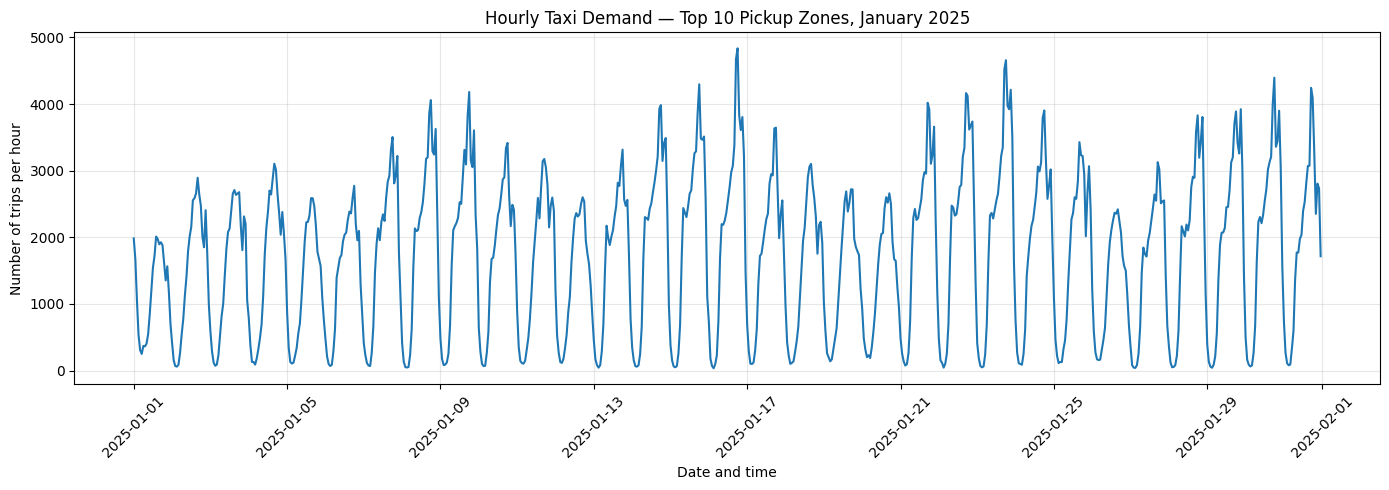

In [ ]:
import matplotlib.pyplot as plt

# Total trips across our 10 selected zones for each hour
hourly_total = (
    complete_demand
    .groupby("pickup_hour")["trip_count"]
    .sum()
)

plt.figure(figsize=(14, 5))
plt.plot(hourly_total.index, hourly_total.values)

plt.title("Hourly Taxi Demand — Top 10 Pickup Zones, January 2025")
plt.xlabel("Date and time")
plt.ylabel("Number of trips per hour")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Average combined trips by hour of day:


,average_trips
pickup_hour,
0,694.5
1,319.4
2,155.5
3,100.2
4,106.7
5,232.5
6,539.4
7,1137.0
8,1550.0


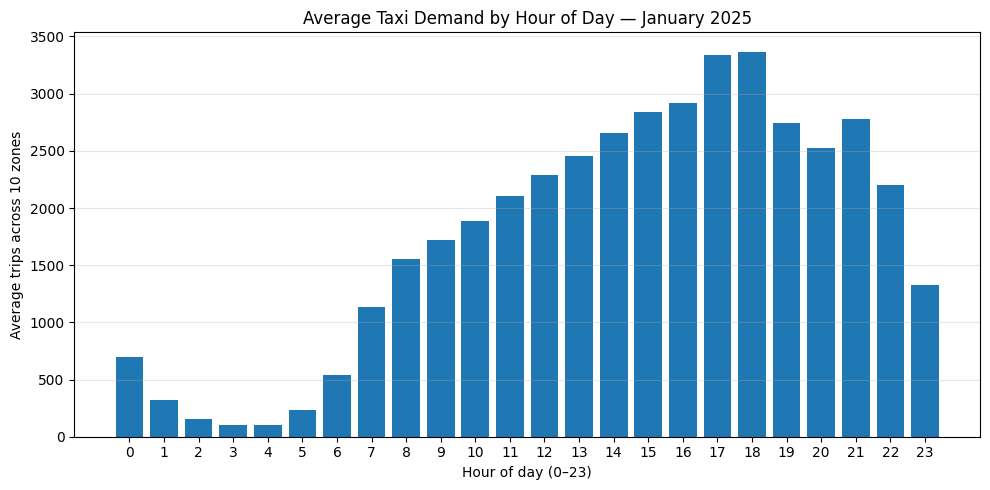

In [ ]:
# First, calculate total trips across our 10 zones for each timestamp
daily_hourly_totals = (
    complete_demand
    .groupby("pickup_hour")["trip_count"]
    .sum()
)

# Then average demand for each hour of the day across January
average_by_hour = (
    daily_hourly_totals
    .groupby(daily_hourly_totals.index.hour)
    .mean()
)

print("Average combined trips by hour of day:")
display(average_by_hour.round(1).rename("average_trips").to_frame())

# Visualise the daily pattern
plt.figure(figsize=(10, 5))
plt.bar(average_by_hour.index, average_by_hour.values)

plt.title("Average Taxi Demand by Hour of Day — January 2025")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Average trips across 10 zones")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Sort chronologically within each pickup zone
model_data = complete_demand.sort_values(
    ["PULocationID", "pickup_hour"]
).copy()

# Create features using past and current observations
grouped = model_data.groupby("PULocationID")["trip_count"]

model_data["current_demand"] = model_data["trip_count"]
model_data["previous_hour_demand"] = grouped.shift(1)
model_data["previous_day_same_hour"] = grouped.shift(24)

# Target: demand one hour into the future
model_data["target_next_hour"] = grouped.shift(-1)

# Remove rows where required historical values or target are unavailable
model_data = model_data.dropna().copy()

print("Model-ready dataset shape:", model_data.shape)
display(model_data.head(10))

Model-ready dataset shape: (7190, 7)


,pickup_hour,PULocationID,trip_count,current_demand,previous_hour_demand,previous_day_same_hour,target_next_hour
243,2025-01-02 00:00:00,132,209,209,302.0,233.0,78.0
253,2025-01-02 01:00:00,132,78,78,209.0,74.0,21.0
263,2025-01-02 02:00:00,132,21,21,78.0,72.0,16.0
273,2025-01-02 03:00:00,132,16,16,21.0,20.0,44.0
283,2025-01-02 04:00:00,132,44,44,16.0,23.0,127.0
293,2025-01-02 05:00:00,132,127,127,44.0,87.0,218.0
303,2025-01-02 06:00:00,132,218,218,127.0,168.0,143.0
313,2025-01-02 07:00:00,132,143,143,218.0,126.0,162.0
323,2025-01-02 08:00:00,132,162,162,143.0,110.0,145.0
333,2025-01-02 09:00:00,132,145,145,162.0,105.0,221.0


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Add time-based features
model_data["hour_of_day"] = model_data["pickup_hour"].dt.hour
model_data["day_of_week"] = model_data["pickup_hour"].dt.dayofweek

# Train on earlier dates; test on the final 7 days
split_date = pd.Timestamp("2025-01-25")

train = model_data[model_data["pickup_hour"] < split_date].copy()
test = model_data[model_data["pickup_hour"] >= split_date].copy()

features = [
    "current_demand",
    "previous_hour_demand",
    "previous_day_same_hour",
    "hour_of_day",
    "day_of_week"
]

X_train = train[features]
y_train = train["target_next_hour"]

X_test = test[features]
y_test = test["target_next_hour"]

print("Training rows:", len(train))
print("Testing rows:", len(test))
print("Training dates:", train["pickup_hour"].min(), "to",
      train["pickup_hour"].max())
print("Testing dates:", test["pickup_hour"].min(), "to",
      test["pickup_hour"].max())

Training rows: 5520
Testing rows: 1670
Training dates: 2025-01-02 00:00:00 to 2025-01-24 23:00:00
Testing dates: 2025-01-25 00:00:00 to 2025-01-31 22:00:00


In [ ]:
# Train the Random Forest
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# Predict next-hour demand
rf_predictions = model.predict(X_test)

# Baseline: next hour equals current hour
baseline_predictions = X_test["current_demand"].to_numpy()

# Evaluate both methods
def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    print(f"\n{name}")
    print(f"MAE:  {mae:.2f} trips")
    print(f"RMSE: {rmse:.2f} trips")

evaluate_model("Baseline", y_test, baseline_predictions)
evaluate_model("Random Forest", y_test, rf_predictions)


Baseline
MAE:  45.72 trips
RMSE: 68.46 trips

Random Forest
MAE:  30.09 trips
RMSE: 47.51 trips


Feature importance:


,Feature,Importance
0,current_demand,0.852535
3,hour_of_day,0.089584
2,previous_day_same_hour,0.024236
1,previous_hour_demand,0.023254
4,day_of_week,0.010391



Actual vs predicted demand:


,Actual,Baseline,Random_Forest
5763,28.0,112,38.5
5773,3.0,28,12.2
5783,8.0,3,6.9
5793,22.0,8,6.9
5803,39.0,22,31.5
5813,124.0,39,85.6
5823,138.0,124,184.1
5833,113.0,138,156.8
5843,108.0,113,121.9
5853,109.0,108,130.6


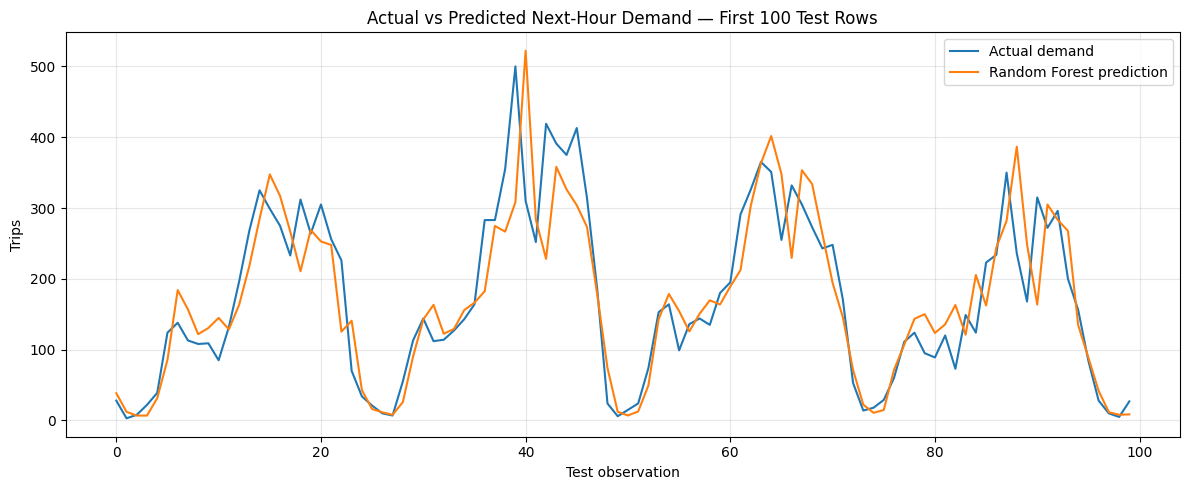

In [ ]:
# 1. Understand which features matter most
importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

print("Feature importance:")
display(importance)

# 2. Compare actual and predicted demand
comparison = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Baseline": baseline_predictions,
    "Random_Forest": rf_predictions
}, index=y_test.index)

print("\nActual vs predicted demand:")
display(comparison.head(15).round(1))

# 3. Plot actual vs predicted demand
plt.figure(figsize=(12, 5))
plt.plot(
    comparison["Actual"].to_numpy()[:100],
    label="Actual demand"
)
plt.plot(
    comparison["Random_Forest"].to_numpy()[:100],
    label="Random Forest prediction"
)

plt.title("Actual vs Predicted Next-Hour Demand — First 100 Test Rows")
plt.xlabel("Test observation")
plt.ylabel("Trips")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

numeric_features = [
    "current_demand",
    "previous_hour_demand",
    "previous_day_same_hour",
    "hour_of_day",
    "day_of_week"
]

categorical_features = ["PULocationID"]

preprocessor = ColumnTransformer(
    transformers=[
        ("zone", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numeric", "passthrough", numeric_features)
    ]
)

zone_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

zone_model.fit(
    train[categorical_features + numeric_features],
    y_train
)

zone_predictions = zone_model.predict(
    test[categorical_features + numeric_features]
)

evaluate_model("Random Forest with pickup zone", y_test, zone_predictions)


Random Forest with pickup zone
MAE:  26.97 trips
RMSE: 42.81 trips


In [ ]:
import joblib

# Save the prepared hourly dataset
complete_demand.to_csv(
    "nyc_taxi_hourly_demand_january_2025.csv",
    index=False
)

# Save the zone-aware model
joblib.dump(
    zone_model,
    "nyc_taxi_zone_aware_random_forest.joblib"
)

print("Saved hourly demand CSV.")
print("Saved zone-aware Random Forest model.")

Saved hourly demand CSV.
Saved zone-aware Random Forest model.


In [ ]:
!wget -q --show-progress \
"https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-02.parquet" \
-O yellow_tripdata_2025-02.parquet

yellow_tripdata_202 100%[===================>]  57.55M   204MB/s    in 0.3s    


In [ ]:
feb_df = pd.read_parquet("yellow_tripdata_2025-02.parquet")

print("February dataset shape:", feb_df.shape)
print("\nPickup timestamp range:")
print(feb_df["tpep_pickup_datetime"].min())
print(feb_df["tpep_pickup_datetime"].max())

print("\nMissing pickup timestamps:",
      feb_df["tpep_pickup_datetime"].isnull().sum())

print("Missing pickup-zone IDs:",
      feb_df["PULocationID"].isnull().sum())


February dataset shape: (3577543, 20)

Pickup timestamp range:
2025-01-31 22:22:53
2025-03-01 00:06:32

Missing pickup timestamps: 0
Missing pickup-zone IDs: 0


In [ ]:
# Keep only February 2025 pickups in our selected zones
february_df = feb_df.loc[
    (feb_df["tpep_pickup_datetime"] >= "2025-02-01") &
    (feb_df["tpep_pickup_datetime"] < "2025-03-01") &
    (feb_df["PULocationID"].isin(top_zones)),
    ["tpep_pickup_datetime", "PULocationID"]
].copy()

# Round pickups down to the hour
february_df["pickup_hour"] = (
    february_df["tpep_pickup_datetime"].dt.floor("h")
)

# Count trips per hour and zone
february_hourly = (
    february_df
    .groupby(["pickup_hour", "PULocationID"])
    .size()
    .reset_index(name="trip_count")
)

print("February selected-zone trips:", len(february_df))
print("February hourly demand shape:", february_hourly.shape)
print("Total trips after aggregation:", february_hourly["trip_count"].sum())

display(february_hourly.head())

February selected-zone trips: 1226277
February hourly demand shape: (6687, 3)
Total trips after aggregation: 1226277


,pickup_hour,PULocationID,trip_count
0,2025-02-01,132,121
1,2025-02-01,142,97
2,2025-02-01,161,115
3,2025-02-01,162,85
4,2025-02-01,163,93


In [ ]:
# Generate all 672 hours in February 2025
feb_hours = pd.date_range(
    start="2025-02-01 00:00:00",
    end="2025-02-28 23:00:00",
    freq="h"
)

# Create every hour-zone combination
feb_index = pd.MultiIndex.from_product(
    [feb_hours, top_zones],
    names=["pickup_hour", "PULocationID"]
)

# Insert zero for hour-zone combinations with no recorded trips
february_complete = (
    february_hourly
    .set_index(["pickup_hour", "PULocationID"])["trip_count"]
    .reindex(feb_index, fill_value=0)
    .reset_index()
)

print("February complete dataset:", february_complete.shape)
print("Expected rows:", 672 * len(top_zones))
print(
    "Zero-demand rows:",
    (february_complete["trip_count"] == 0).sum()
)

display(february_complete.head(10))

February complete dataset: (6720, 3)
Expected rows: 6720
Zero-demand rows: 33


,pickup_hour,PULocationID,trip_count
0,2025-02-01,161,115
1,2025-02-01,237,110
2,2025-02-01,236,55
3,2025-02-01,132,121
4,2025-02-01,230,163
5,2025-02-01,186,141
6,2025-02-01,162,85
7,2025-02-01,142,97
8,2025-02-01,239,81
9,2025-02-01,163,93


In [ ]:
# Combine the two months
combined_demand = pd.concat(
    [complete_demand, february_complete],
    ignore_index=True
)

# Sort by zone and time for time-series features
combined_demand = combined_demand.sort_values(
    ["PULocationID", "pickup_hour"]
).reset_index(drop=True)

print("Combined dataset shape:", combined_demand.shape)
print("Expected rows:", (744 + 672) * len(top_zones))
print("Earliest hour:", combined_demand["pickup_hour"].min())
print("Latest hour:", combined_demand["pickup_hour"].max())

# Confirm each hour-zone combination is unique
print(
    "Duplicate hour-zone combinations:",
    combined_demand.duplicated(
        ["pickup_hour", "PULocationID"]
    ).sum()
)

Combined dataset shape: (14160, 3)
Expected rows: 14160
Earliest hour: 2025-01-01 00:00:00
Latest hour: 2025-02-28 23:00:00
Duplicate hour-zone combinations: 0


In [ ]:
# Create time-based features over the combined timeline
combined_demand["hour_of_day"] = (
    combined_demand["pickup_hour"].dt.hour
)

combined_demand["day_of_week"] = (
    combined_demand["pickup_hour"].dt.dayofweek
)

# Create historical features within each pickup zone
grouped = combined_demand.groupby("PULocationID")["trip_count"]

combined_demand["current_demand"] = combined_demand["trip_count"]
combined_demand["previous_hour_demand"] = grouped.shift(1)
combined_demand["previous_day_same_hour"] = grouped.shift(24)

# Create the next-hour target
combined_demand["target_next_hour"] = grouped.shift(-1)

# Select February records with all required features
february_test = combined_demand.loc[
    (combined_demand["pickup_hour"] >= "2025-02-01") &
    (combined_demand["pickup_hour"] < "2025-03-01")
].dropna().copy()

print("February test rows:", len(february_test))
print("February test starts:", february_test["pickup_hour"].min())
print("February test ends:", february_test["pickup_hour"].max())

display(february_test.head())

February test rows: 6710
February test starts: 2025-02-01 00:00:00
February test ends: 2025-02-28 22:00:00


,pickup_hour,PULocationID,trip_count,hour_of_day,day_of_week,current_demand,previous_hour_demand,previous_day_same_hour,target_next_hour
744,2025-02-01 00:00:00,132,121,0,5,121,270.0,177.0,44.0
745,2025-02-01 01:00:00,132,44,1,5,44,121.0,49.0,1.0
746,2025-02-01 02:00:00,132,1,2,5,1,44.0,8.0,9.0
747,2025-02-01 03:00:00,132,9,3,5,9,1.0,13.0,21.0
748,2025-02-01 04:00:00,132,21,4,5,21,9.0,23.0,73.0


In [ ]:
# Use the same features as the January-trained model
feb_features = [
    "PULocationID",
    "current_demand",
    "previous_hour_demand",
    "previous_day_same_hour",
    "hour_of_day",
    "day_of_week"
]

X_feb = february_test[feb_features]
y_feb = february_test["target_next_hour"]

# Predict using the model trained on January
feb_predictions = zone_model.predict(X_feb)

# Baseline: next-hour demand equals current-hour demand
feb_baseline = X_feb["current_demand"].to_numpy()

# Evaluate on February
evaluate_model("February baseline", y_feb, feb_baseline)
evaluate_model("January-trained model on February", y_feb, feb_predictions)



February baseline
MAE:  44.71 trips
RMSE: 65.40 trips

January-trained model on February
MAE:  26.36 trips
RMSE: 40.77 trips


In [ ]:
!wget -q --show-progress \
"https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-03.parquet" \
-O yellow_tripdata_2025-03.parquet

yellow_tripdata_202 100%[===================>]  66.72M   168MB/s    in 0.4s    


In [ ]:
mar_df = pd.read_parquet("yellow_tripdata_2025-03.parquet")

print("March dataset shape:", mar_df.shape)
print("Earliest pickup:",
      mar_df["tpep_pickup_datetime"].min())
print("Latest pickup:",
      mar_df["tpep_pickup_datetime"].max())
print("Missing pickup timestamps:",
      mar_df["tpep_pickup_datetime"].isnull().sum())
print("Missing pickup-zone IDs:",
      mar_df["PULocationID"].isnull().sum())

March dataset shape: (4145257, 20)
Earliest pickup: 2007-12-05 18:45:00
Latest pickup: 2025-04-01 00:00:17
Missing pickup timestamps: 0
Missing pickup-zone IDs: 0


In [ ]:
pickup_time = mar_df["tpep_pickup_datetime"]

# Count records by calendar month
print("Trips by month:")
display(
    pickup_time.dt.to_period("M")
    .value_counts()
    .sort_index()
    .to_frame("trip_count")
)

# Count pickups outside March 2025
outside_march = (
    (pickup_time < "2025-03-01") |
    (pickup_time >= "2025-04-01")
)

print("\nRecords outside March 2025:", outside_march.sum())

# Inspect the earliest 10 pickup timestamps
print("\nEarliest pickup records:")
display(
    mar_df.nsmallest(10, "tpep_pickup_datetime")[
        ["tpep_pickup_datetime", "PULocationID", "DOLocationID"]
    ]
)

Trips by month:


,trip_count
tpep_pickup_datetime,
2007-12,1
2009-01,1
2025-02,29
2025-03,4145224
2025-04,2



Records outside March 2025: 33

Earliest pickup records:


,tpep_pickup_datetime,PULocationID,DOLocationID
827675,2007-12-05 18:45:00,142,234
230843,2009-01-01 00:19:34,138,239
3059,2025-02-28 22:28:34,161,238
3060,2025-02-28 22:40:35,239,239
3061,2025-02-28 23:03:25,163,68
7531,2025-02-28 23:15:23,68,239
3147,2025-02-28 23:25:17,234,33
7532,2025-02-28 23:35:22,48,42
3763,2025-02-28 23:35:43,100,90
863,2025-02-28 23:43:49,236,238


In [ ]:
# Keep March 2025 trips from our 10 selected pickup zones
march_df = mar_df.loc[
    (mar_df["tpep_pickup_datetime"] >= "2025-03-01") &
    (mar_df["tpep_pickup_datetime"] < "2025-04-01") &
    (mar_df["PULocationID"].isin(top_zones)),
    ["tpep_pickup_datetime", "PULocationID"]
].copy()

# Round pickup times down to the hour
march_df["pickup_hour"] = (
    march_df["tpep_pickup_datetime"].dt.floor("h")
)

# Count trips by hour and pickup zone
march_hourly = (
    march_df
    .groupby(["pickup_hour", "PULocationID"])
    .size()
    .reset_index(name="trip_count")
)

print("March selected-zone trips:", len(march_df))
print("March hourly demand shape:", march_hourly.shape)
print("Trips after aggregation:", march_hourly["trip_count"].sum())
print("Earliest included pickup:", march_df["tpep_pickup_datetime"].min())
print("Latest included pickup:", march_df["tpep_pickup_datetime"].max())

March selected-zone trips: 1396261
March hourly demand shape: (7412, 3)
Trips after aggregation: 1396261
Earliest included pickup: 2025-03-01 00:00:00
Latest included pickup: 2025-03-31 23:59:59


In [ ]:
# Generate every hour in March 2025
march_hours = pd.date_range(
    start="2025-03-01 00:00:00",
    end="2025-03-31 23:00:00",
    freq="h"
)

# Create all hour-zone combinations
march_index = pd.MultiIndex.from_product(
    [march_hours, top_zones],
    names=["pickup_hour", "PULocationID"]
)

# Fill combinations with no recorded trips with zero
march_complete = (
    march_hourly
    .set_index(["pickup_hour", "PULocationID"])["trip_count"]
    .reindex(march_index, fill_value=0)
    .reset_index()
)

print("March complete dataset:", march_complete.shape)
print("Expected rows:", 744 * len(top_zones))
print("Zero-demand rows:",
      (march_complete["trip_count"] == 0).sum())

display(march_complete.head(10))

March complete dataset: (7440, 3)
Expected rows: 7440
Zero-demand rows: 28


,pickup_hour,PULocationID,trip_count
0,2025-03-01,161,163
1,2025-03-01,237,138
2,2025-03-01,236,52
3,2025-03-01,132,187
4,2025-03-01,230,251
5,2025-03-01,186,167
6,2025-03-01,162,96
7,2025-03-01,142,114
8,2025-03-01,239,105
9,2025-03-01,163,128


In [ ]:
# Combine the complete monthly datasets
three_month_demand = pd.concat(
    [complete_demand, february_complete, march_complete],
    ignore_index=True
)

three_month_demand = three_month_demand.sort_values(
    ["PULocationID", "pickup_hour"]
).reset_index(drop=True)

print("Combined dataset shape:", three_month_demand.shape)
print("Expected rows:", 2160 * len(top_zones))

print("Earliest hour:",
      three_month_demand["pickup_hour"].min())
print("Latest hour:",
      three_month_demand["pickup_hour"].max())

print(
    "Duplicate hour-zone combinations:",
    three_month_demand.duplicated(
        ["pickup_hour", "PULocationID"]
    ).sum()
)

print(
    "Total trips across all months:",
    three_month_demand["trip_count"].sum()
)

Combined dataset shape: (21600, 3)
Expected rows: 21600
Earliest hour: 2025-01-01 00:00:00
Latest hour: 2025-03-31 23:00:00
Duplicate hour-zone combinations: 0
Total trips across all months: 3923992


In [ ]:
# Sort the complete dataset chronologically within each zone
forecast_data = three_month_demand.sort_values(
    ["PULocationID", "pickup_hour"]
).copy()

# Calendar features
forecast_data["hour_of_day"] = forecast_data["pickup_hour"].dt.hour
forecast_data["day_of_week"] = forecast_data["pickup_hour"].dt.dayofweek

# Historical demand features, calculated separately for each zone
grouped = forecast_data.groupby("PULocationID")["trip_count"]

forecast_data["current_demand"] = forecast_data["trip_count"]
forecast_data["previous_hour_demand"] = grouped.shift(1)
forecast_data["previous_day_same_hour"] = grouped.shift(24)

# Predict the next hour's demand
forecast_data["target_next_hour"] = grouped.shift(-1)

# Remove rows without the required historical values or target
forecast_data = forecast_data.dropna().copy()

# January and February training period.
# Exclude Feb 28 at 23:00 because its target falls in March.
train_end = pd.Timestamp("2025-02-28 23:00:00")
march_start = pd.Timestamp("2025-03-01 00:00:00")

train_3m = forecast_data[
    forecast_data["pickup_hour"] < train_end
].copy()

march_test = forecast_data[
    forecast_data["pickup_hour"] >= march_start
].copy()

print("Training rows:", len(train_3m))
print("March test rows:", len(march_test))
print("Training ends:", train_3m["pickup_hour"].max())
print("March test starts:", march_test["pickup_hour"].min())
print("March test ends:", march_test["pickup_hour"].max())

Training rows: 13910
March test rows: 7430
Training ends: 2025-02-28 22:00:00
March test starts: 2025-03-01 00:00:00
March test ends: 2025-03-31 22:00:00


In [ ]:
# Define the same features used by our existing zone-aware model
features = [
    "PULocationID",
    "current_demand",
    "previous_hour_demand",
    "previous_day_same_hour",
    "hour_of_day",
    "day_of_week"
]

# Prepare training and test data
X_train_3m = train_3m[features]
y_train_3m = train_3m["target_next_hour"]

X_march = march_test[features]
y_march = march_test["target_next_hour"]

# Train a new model on January and February
model_3m = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

model_3m.fit(X_train_3m, y_train_3m)

# Generate predictions on the same March test rows
march_baseline = X_march["current_demand"].to_numpy()
march_jan_predictions = zone_model.predict(X_march)
march_3m_predictions = model_3m.predict(X_march)

# Evaluate all three methods
evaluate_model("March baseline", y_march, march_baseline)
evaluate_model("January-trained model on March",
               y_march, march_jan_predictions)
evaluate_model("January-February model on March",
               y_march, march_3m_predictions)


March baseline
MAE:  44.15 trips
RMSE: 64.74 trips

January-trained model on March
MAE:  27.80 trips
RMSE: 43.25 trips

January-February model on March
MAE:  26.12 trips
RMSE: 41.10 trips


In [ ]:
import joblib
import json

# Save the best current candidate model
joblib.dump(
    model_3m,
    "nyc_taxi_random_forest_jan_feb_2025.joblib"
)

# Store the March evaluation metrics
march_results = {
    "Persistence baseline": {
        "MAE": mean_absolute_error(y_march, march_baseline),
        "RMSE": np.sqrt(mean_squared_error(y_march, march_baseline))
    },
    "January-trained model": {
        "MAE": mean_absolute_error(y_march, march_jan_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_march, march_jan_predictions))
    },
    "January-February model": {
        "MAE": mean_absolute_error(y_march, march_3m_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_march, march_3m_predictions))
    }
}

with open("march_2025_evaluation.json", "w") as f:
    json.dump(march_results, f, indent=4)

print("Saved January-February model.")
print("Saved March evaluation results.")

Saved January-February model.
Saved March evaluation results.


In [ ]:
# Create a table of actual and predicted March demand
march_predictions_df = march_test[
    ["pickup_hour", "PULocationID", "target_next_hour"]
].copy()

march_predictions_df = march_predictions_df.rename(
    columns={"target_next_hour": "actual_next_hour"}
)

march_predictions_df["predicted_next_hour"] = march_3m_predictions

march_predictions_df["baseline_prediction"] = march_baseline

# Calculate the prediction error
march_predictions_df["absolute_error"] = (
    march_predictions_df["actual_next_hour"]
    - march_predictions_df["predicted_next_hour"]
).abs()

print("Prediction results shape:", march_predictions_df.shape)
display(march_predictions_df.head(10))

Prediction results shape: (7430, 6)


,pickup_hour,PULocationID,actual_next_hour,predicted_next_hour,baseline_prediction,absolute_error
1416,2025-03-01 00:00:00,132,43.0,91.121825,187,48.121825
1417,2025-03-01 01:00:00,132,6.0,29.395364,43,23.395364
1418,2025-03-01 02:00:00,132,24.0,16.655082,6,7.344918
1419,2025-03-01 03:00:00,132,23.0,21.128631,24,1.871369
1420,2025-03-01 04:00:00,132,66.0,86.917519,23,20.917519
1421,2025-03-01 05:00:00,132,158.0,111.091761,66,46.908239
1422,2025-03-01 06:00:00,132,182.0,165.586261,158,16.413739
1423,2025-03-01 07:00:00,132,129.0,183.473085,182,54.473085
1424,2025-03-01 08:00:00,132,100.0,138.316582,129,38.316582
1425,2025-03-01 09:00:00,132,76.0,114.896861,100,38.896861


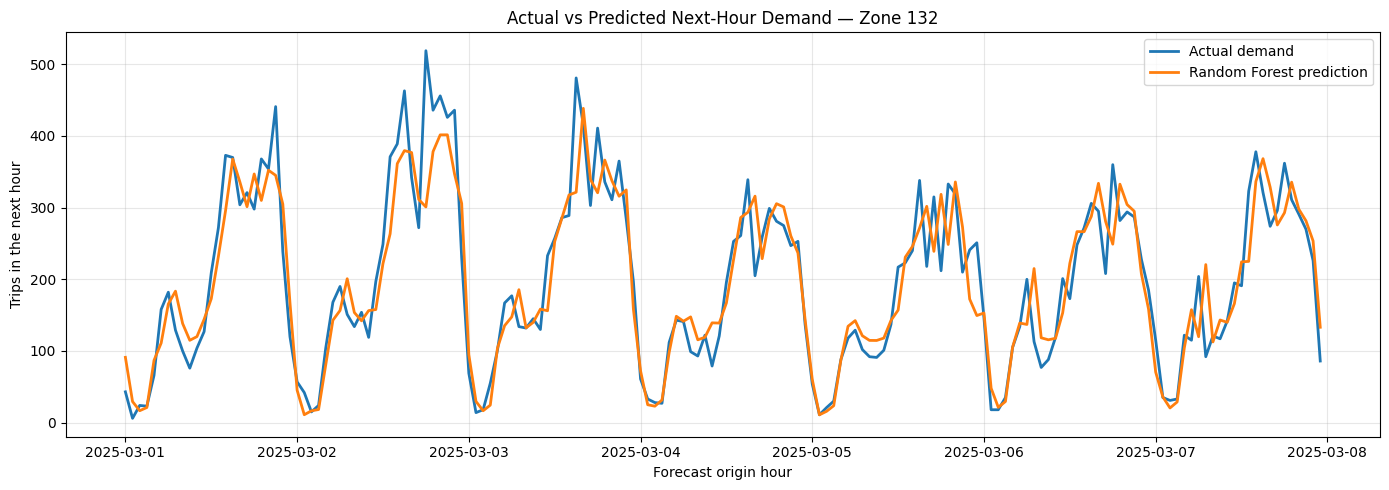

In [ ]:
import matplotlib.pyplot as plt

# Select one pickup zone and the first seven days of March
zone_132 = march_predictions_df[
    (march_predictions_df["PULocationID"] == 132) &
    (march_predictions_df["pickup_hour"] < "2025-03-08")
].copy()

# Plot actual and predicted next-hour demand
plt.figure(figsize=(14, 5))

plt.plot(
    zone_132["pickup_hour"],
    zone_132["actual_next_hour"],
    label="Actual demand",
    linewidth=2
)

plt.plot(
    zone_132["pickup_hour"],
    zone_132["predicted_next_hour"],
    label="Random Forest prediction",
    linewidth=2
)

plt.title("Actual vs Predicted Next-Hour Demand — Zone 132")
plt.xlabel("Forecast origin hour")
plt.ylabel("Trips in the next hour")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Prediction errors by pickup zone:


,PULocationID,MAE,Mean_Error,RMSE
0,132,38.37,-9.59,53.17
1,186,32.09,-6.26,48.51
2,161,29.14,-4.18,47.06
3,142,27.45,-2.45,47.83
4,230,26.42,-4.72,41.65
5,162,24.29,-0.41,37.56
6,237,24.08,-1.56,36.25
7,236,22.41,5.68,33.90
8,163,19.20,-1.44,29.29
9,239,17.73,0.60,27.20


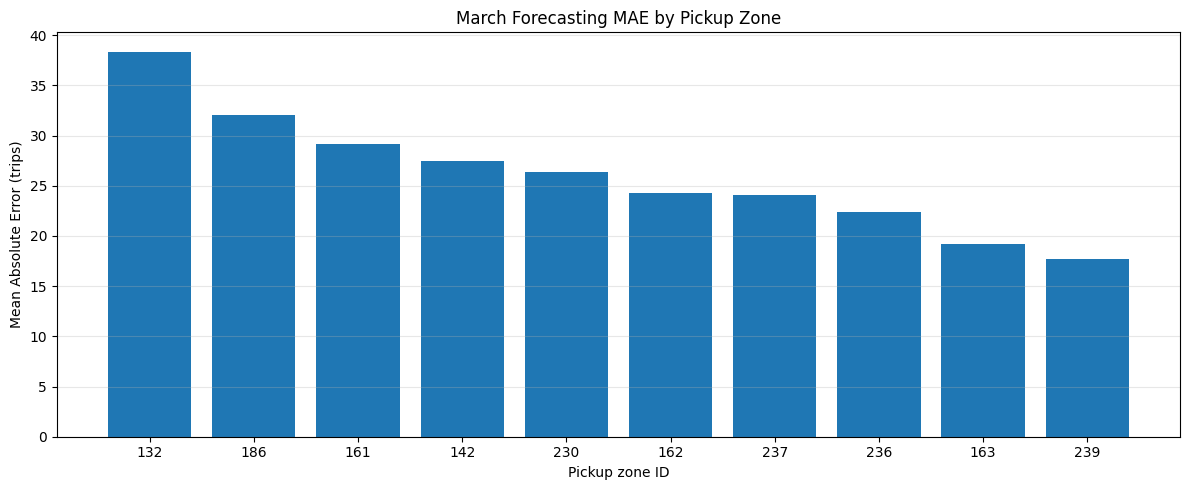

In [ ]:
# Calculate signed prediction error
march_predictions_df["error"] = (
    march_predictions_df["predicted_next_hour"]
    - march_predictions_df["actual_next_hour"]
)

# Summarise model performance by pickup zone
zone_errors = (
    march_predictions_df
    .groupby("PULocationID")
    .agg(
        MAE=("absolute_error", "mean"),
        Mean_Error=("error", "mean"),
        RMSE=("error", lambda x: np.sqrt((x ** 2).mean()))
    )
    .sort_values("MAE", ascending=False)
    .reset_index()
)

print("Prediction errors by pickup zone:")
display(zone_errors.round(2))

# Visualise MAE by zone
plt.figure(figsize=(12, 5))
plt.bar(
    zone_errors["PULocationID"].astype(str),
    zone_errors["MAE"]
)

plt.title("March Forecasting MAE by Pickup Zone")
plt.xlabel("Pickup zone ID")
plt.ylabel("Mean Absolute Error (trips)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Forecasting errors by hour of day:


,hour_of_day,MAE,Mean_Error,RMSE
0,0,12.35,2.00,28.18
1,1,6.95,2.30,14.51
2,2,6.18,-1.58,18.25
3,3,4.44,-1.62,6.82
4,4,5.96,-2.62,8.72
5,5,11.37,-0.97,18.57
6,6,19.89,2.98,30.01
7,7,22.50,-3.76,33.15
8,8,21.72,2.46,29.86
9,9,24.10,4.72,31.61


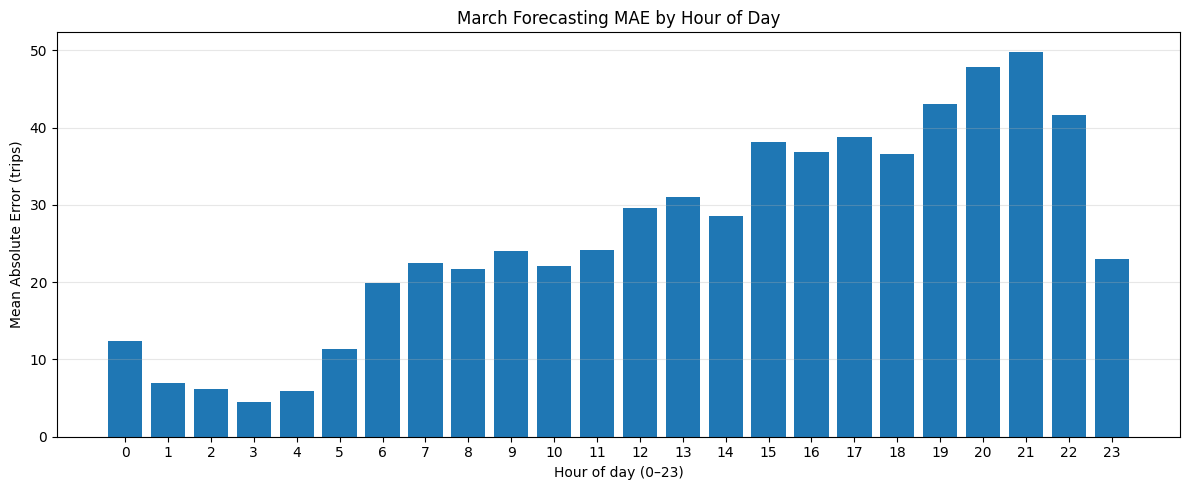

In [ ]:
# Summarise errors by hour of day
march_predictions_df["hour_of_day"] = (
    march_predictions_df["pickup_hour"].dt.hour
)

hour_errors = (
    march_predictions_df
    .groupby("hour_of_day")
    .agg(
        MAE=("absolute_error", "mean"),
        Mean_Error=("error", "mean"),
        RMSE=("error", lambda x: np.sqrt((x ** 2).mean()))
    )
    .reset_index()
)

print("Forecasting errors by hour of day:")
display(hour_errors.round(2))

# Plot MAE for each hour
plt.figure(figsize=(12, 5))

plt.bar(
    hour_errors["hour_of_day"],
    hour_errors["MAE"]
)

plt.xticks(range(24))
plt.title("March Forecasting MAE by Hour of Day")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Mean Absolute Error (trips)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Demand and relative errors by hour:


,hour_of_day,average_actual_demand,MAE,relative_MAE_percent
0,0,41.19,12.35,29.99
1,1,17.86,6.95,38.89
2,2,12.87,6.18,48.00
3,3,13.51,4.44,32.84
4,4,26.96,5.96,22.11
5,5,58.13,11.37,19.55
6,6,116.36,19.89,17.09
7,7,162.38,22.50,13.86
8,8,182.90,21.72,11.88
9,9,197.81,24.10,12.18


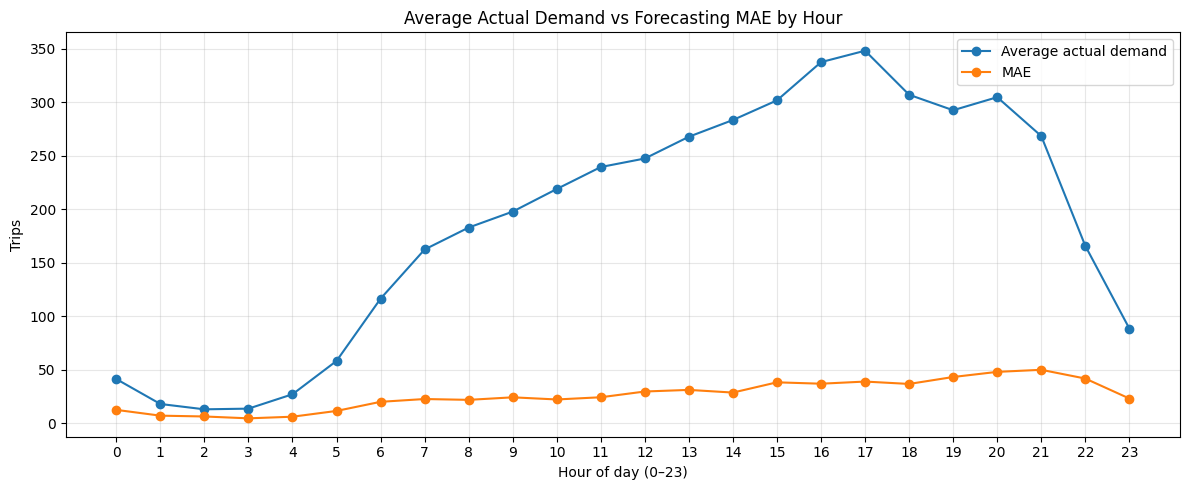

In [ ]:
# Calculate average actual demand by hour
hour_errors["average_actual_demand"] = (
    march_predictions_df
    .groupby("hour_of_day")["actual_next_hour"]
    .mean()
    .reindex(hour_errors["hour_of_day"])
    .to_numpy()
)

# Relative MAE as a percentage of average actual demand
hour_errors["relative_MAE_percent"] = (
    hour_errors["MAE"]
    / hour_errors["average_actual_demand"]
) * 100

print("Demand and relative errors by hour:")
display(
    hour_errors[
        [
            "hour_of_day",
            "average_actual_demand",
            "MAE",
            "relative_MAE_percent"
        ]
    ].round(2)
)

# Compare average demand and MAE
plt.figure(figsize=(12, 5))

plt.plot(
    hour_errors["hour_of_day"],
    hour_errors["average_actual_demand"],
    marker="o",
    label="Average actual demand"
)

plt.plot(
    hour_errors["hour_of_day"],
    hour_errors["MAE"],
    marker="o",
    label="MAE"
)

plt.xticks(range(24))
plt.title("Average Actual Demand vs Forecasting MAE by Hour")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Trips")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Save all March prediction results to CSV
march_predictions_df.to_csv(
    "march_2025_demand_predictions.csv",
    index=False
)

print("March prediction results saved successfully.")
print("Rows:", len(march_predictions_df))
print("Columns:", march_predictions_df.columns.tolist())

March prediction results saved successfully.
Rows: 7430
Columns: ['pickup_hour', 'PULocationID', 'actual_next_hour', 'predicted_next_hour', 'baseline_prediction', 'absolute_error', 'error', 'hour_of_day']


In [ ]:
# Save the complete three-month demand dataset
three_month_demand.to_csv(
    "nyc_taxi_hourly_demand_jan_mar_2025.csv",
    index=False
)

print("Three-month demand dataset saved!")
print("Rows:", len(three_month_demand))
print("Columns:", three_month_demand.columns.tolist())
print(
    "Total trips:",
    three_month_demand["trip_count"].sum()
)

Three-month demand dataset saved!
Rows: 21600
Columns: ['pickup_hour', 'PULocationID', 'trip_count']
Total trips: 3923992


In [ ]:
# Summarise demand for each pickup zone
zone_summary = (
    three_month_demand
    .groupby("PULocationID")
    .agg(
        total_trips=("trip_count", "sum"),
        average_hourly_demand=("trip_count", "mean"),
        highest_hourly_demand=("trip_count", "max")
    )
    .reset_index()
    .sort_values("total_trips", ascending=False)
)

print("Zone summary shape:", zone_summary.shape)
display(zone_summary.round(2))

# Save the summary for Power BI
zone_summary.to_csv(
    "nyc_taxi_zone_summary_jan_mar_2025.csv",
    index=False
)

print("Zone summary CSV saved successfully!")

Zone summary shape: (10, 4)


,PULocationID,total_trips,average_hourly_demand,highest_hourly_demand
2,161,513558,237.76,891
8,237,491956,227.76,679
7,236,456757,211.46,689
0,132,433500,200.69,572
6,230,377215,174.64,708
5,186,365694,169.30,518
3,162,360560,166.93,651
1,142,332383,153.88,635
4,163,296974,137.49,454
9,239,295395,136.76,429


Zone summary CSV saved successfully!
